## Exploração dos dados

Investigamos os tipos, as distribuições, as ausências e as relações entre as variáveis dos registros da Regenera. O arquivo é lido como texto para que o diagnóstico reflita os valores registrados. Conversões usadas em gráficos e tabelas são feitas em uma cópia de trabalho.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

arquivo = Path("Dados_REG.tab")
dados_brutos = pd.read_csv(
    arquivo, sep="\t", encoding="utf-8-sig", dtype="string", keep_default_na=False
)
texto = dados_brutos.apply(lambda coluna: coluna.str.strip())

morfologia = ["Cor", "Cores", "Borda", "Textura", "Forma", "Brilho", "Muco", "Relevo"]
atividades = [f"Atividade {i:02d}" for i in range(1, 24)]
binarias   = ["Atividade 01", "Atividade 03", "Atividade 04", "Atividade 16"]
ordinais   = ["Atividade 13", *[f"Atividade {i:02d}" for i in range(17, 23)]]
continuas  = [coluna for coluna in atividades if coluna not in binarias + ordinais]

ausentes = texto.isin(["", "NA"])
erros_formula = texto.eq("#NÚM!")
observados = texto.mask(ausentes | erros_formula)
numeros = observados[continuas + ordinais + ["Atividade 01", "Cor"]].apply(
    pd.to_numeric, errors="raise"
)

azul = "#276785"
verde = "#168276"
laranja = "#C16A35"

print(f"{len(texto)} registros e {len(texto.columns)} colunas.")

506 registros e 33 colunas.


### Colunas

Cada linha é um registro de isolado. `n°` é um identificador. `Cor` informa quantas cores foram observadas e `Cores` registra seus códigos em ordem de predominância. Os dois campos são complementares e podem estar preenchidos na mesma linha. Em campos morfológicos com múltiplos códigos, a sequência vai do código mais representativo na placa ao menos representativo e é preservada, de modo que `1 & 2` e `2 & 1` aparecem como combinações distintas.

`GRAM` é uma variável nominal. `Positivo` e `Negativo` indicam o resultado da coloração de Gram para bactérias. O arquivo também traz `Levedura` como categoria própria.

Tratamos os níveis de 0 a 3 das atividades 13 e 17 a 22 como ordinais para a exploração. A ordem crescente é uma hipótese de leitura, pois os nomes dos ensaios são anonimizados e o enunciado não detalha o significado de cada nível.

In [11]:
tipos = {
    "n°": "Identificador",
    "GRAM": "Nominal",
    **dict.fromkeys(morfologia, "Nominal"),
    "Cor": "Contagem discreta",
    **dict.fromkeys(binarias, "Binária"),
    **dict.fromkeys(ordinais, "Ordinal (hipótese)"),
    **dict.fromkeys(continuas, "Contínua"),
}

dicionario = pd.DataFrame({
    "Tipo": pd.Series(tipos),
    "Valores distintos observados": observados.nunique(),
    "Ausentes": ausentes.sum(),
    "Erros de fórmula": erros_formula.sum(),
}).loc[texto.columns]
print(dicionario.to_string())

                            Tipo  Valores distintos observados  Ausentes  Erros de fórmula
n°                 Identificador                           505         0                 0
GRAM                     Nominal                             7         0                 0
Cor            Contagem discreta                             2         0                 0
Cores                    Nominal                            26         0                 0
Borda                    Nominal                             3         1                 0
Textura                  Nominal                             4         1                 0
Forma                    Nominal                             7         2                 0
Brilho                   Nominal                             6         2                 0
Muco                     Nominal                             3         2                 0
Relevo                   Nominal                             2         3                 0

### Valores ausentes e erro de fórmula

Células vazias e marcações `NA` representam dados ausentes no experimento. A figura conta essas ausências separadamente do erro de fórmula (`#NÚM!`). Ambos ficam indisponíveis para os resumos numéricos. As porcentagens usam os 506 registros como denominador.

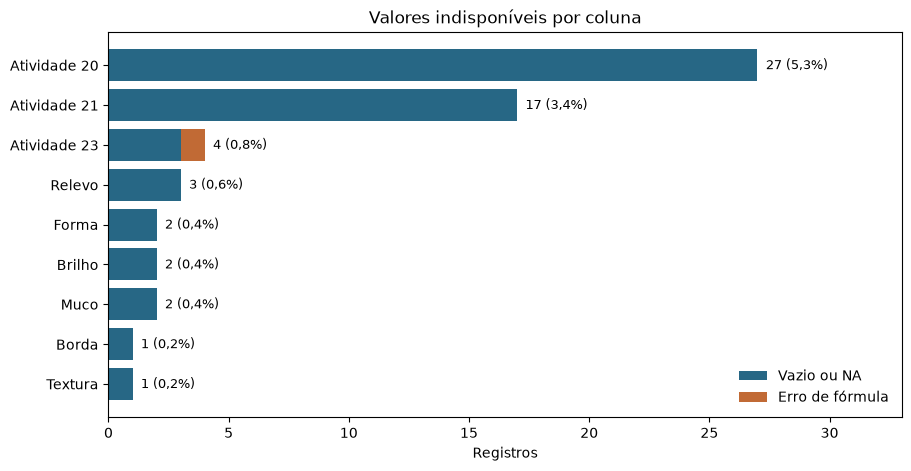

In [12]:
indisponiveis = dicionario[["Ausentes", "Erros de fórmula"]].copy()
indisponiveis["Total"] = indisponiveis.sum(axis=1)
indisponiveis = indisponiveis.loc[indisponiveis["Total"].gt(0)].sort_values(
    "Total", ascending=False
)

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
ax.barh(indisponiveis.index, indisponiveis["Ausentes"], color=azul, label="Vazio ou NA")
ax.barh(
    indisponiveis.index, indisponiveis["Erros de fórmula"],
    left=indisponiveis["Ausentes"], color=laranja, label="Erro de fórmula",
)
for coluna, total in indisponiveis["Total"].items():
    rotulo = f"{total} ({total / len(texto):.1%})".replace(".", ",")
    ax.text(total + 0.35, coluna, rotulo, va="center", fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="Registros", title="Valores indisponíveis por coluna", xlim=(0, 33))
ax.legend(loc="lower right", frameon=False)
plt.show()

As atividades 20 e 21 concentram as ausências, com 27 (5,3%) e 17 (3,4%) células vazias, respectivamente. A Atividade 23 tem três células vazias e um erro de fórmula. Na morfologia, as colunas afetadas têm entre uma e três ausências cada.

### Distribuições de GRAM e morfologia

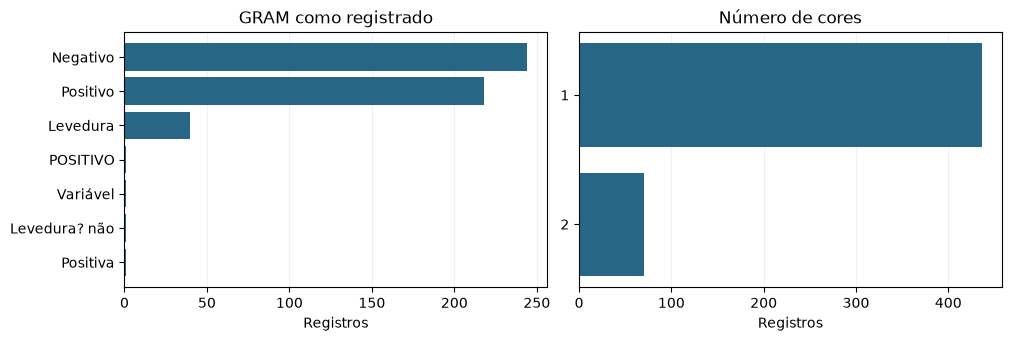

In [13]:
def barras_frequencia(ax, valores, titulo, *, ordenar=False, cor=azul):
    frequencias = valores.value_counts()
    if ordenar:
        frequencias = frequencias.sort_index()
    ax.barh(frequencias.index.map(str), frequencias.to_numpy(), color=cor)
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="Registros")
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.18)

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
barras_frequencia(eixos[0], observados["GRAM"], "GRAM como registrado")
barras_frequencia(eixos[1], numeros["Cor"], "Número de cores", ordenar=True)
plt.show()

**GRAM.** As grafias mais comuns são `Negativo` (244), `Positivo` (218) e `Levedura` (40). As ocorrências unitárias incluem duas variantes de escrita de `Positivo` e dois registros de interpretação ambígua.

**Número de cores.** Há 436 registros (86,2%) com uma cor observada e 70 (13,8%) com duas.

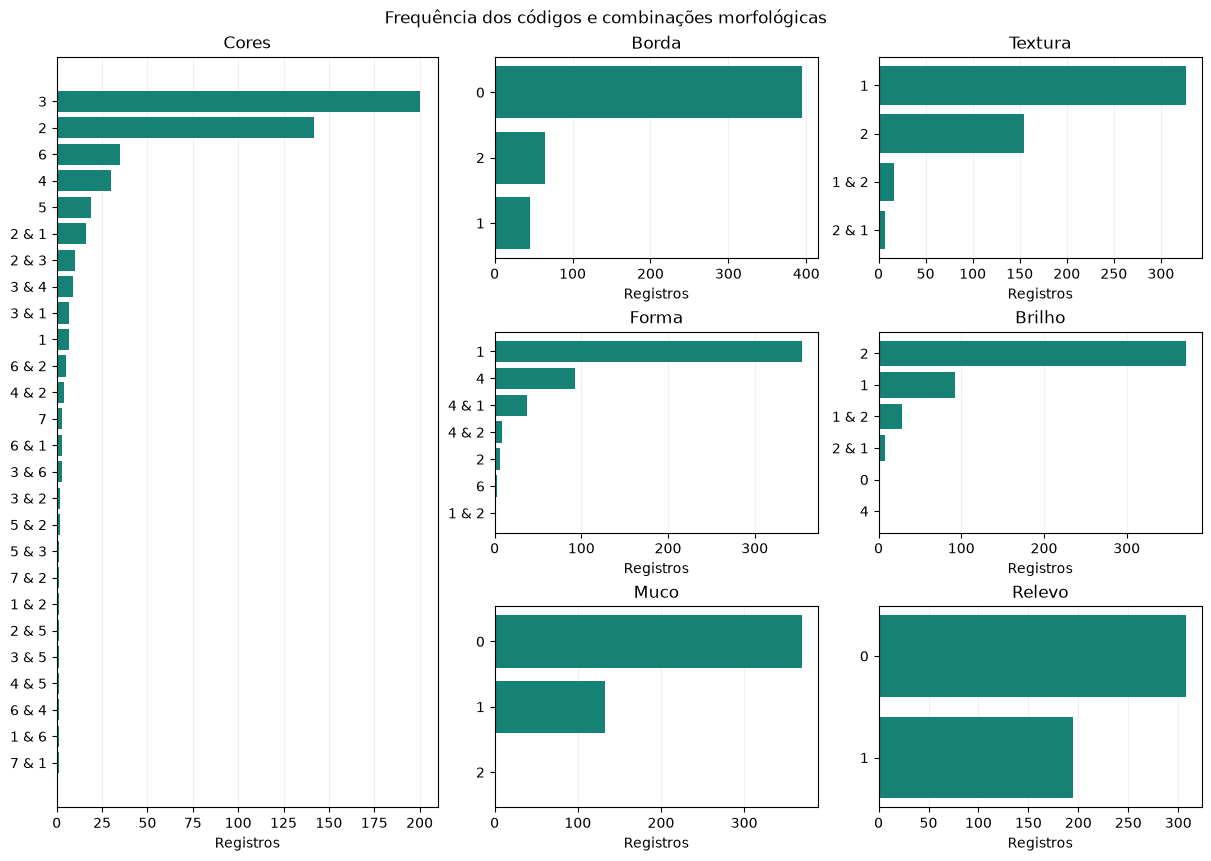

In [14]:
fig = plt.figure(figsize=(12, 8.5), layout="constrained")
grade_morfologia = fig.add_gridspec(1, 2, width_ratios=[1, 2])
ax_cores = fig.add_subplot(grade_morfologia[0, 0])
barras_frequencia(ax_cores, observados["Cores"], "Cores", cor=verde)
grade = grade_morfologia[0, 1].subgridspec(3, 2)
for posicao, coluna in enumerate(morfologia[2:]):
    ax = fig.add_subplot(grade[posicao // 2, posicao % 2])
    barras_frequencia(ax, observados[coluna], coluna, cor=verde)
fig.suptitle("Frequência dos códigos e combinações morfológicas")
plt.show()

**Cores, Borda e Textura.** Em `Cores`, os códigos únicos `3` (200) e `2` (142) são os mais frequentes. Em `Borda`, predomina o código `0` (395), e em `Textura` predomina `1` (327). A ordem faz diferença nas contagens de `Textura`: `1 & 2` aparece 16 vezes e `2 & 1` aparece 7.

**Forma, Brilho, Muco e Relevo.** Os códigos simples dominam: `1` em `Forma` (355), `2` em `Brilho` (372) e `0` em `Muco` (370). `Relevo` tem uma divisão mais próxima entre `0` (308) e `1` (195).

### Distribuições das atividades

As barras abaixo mostram os resultados observados nos ensaios binários e nos que têm níveis de 0 a 3.

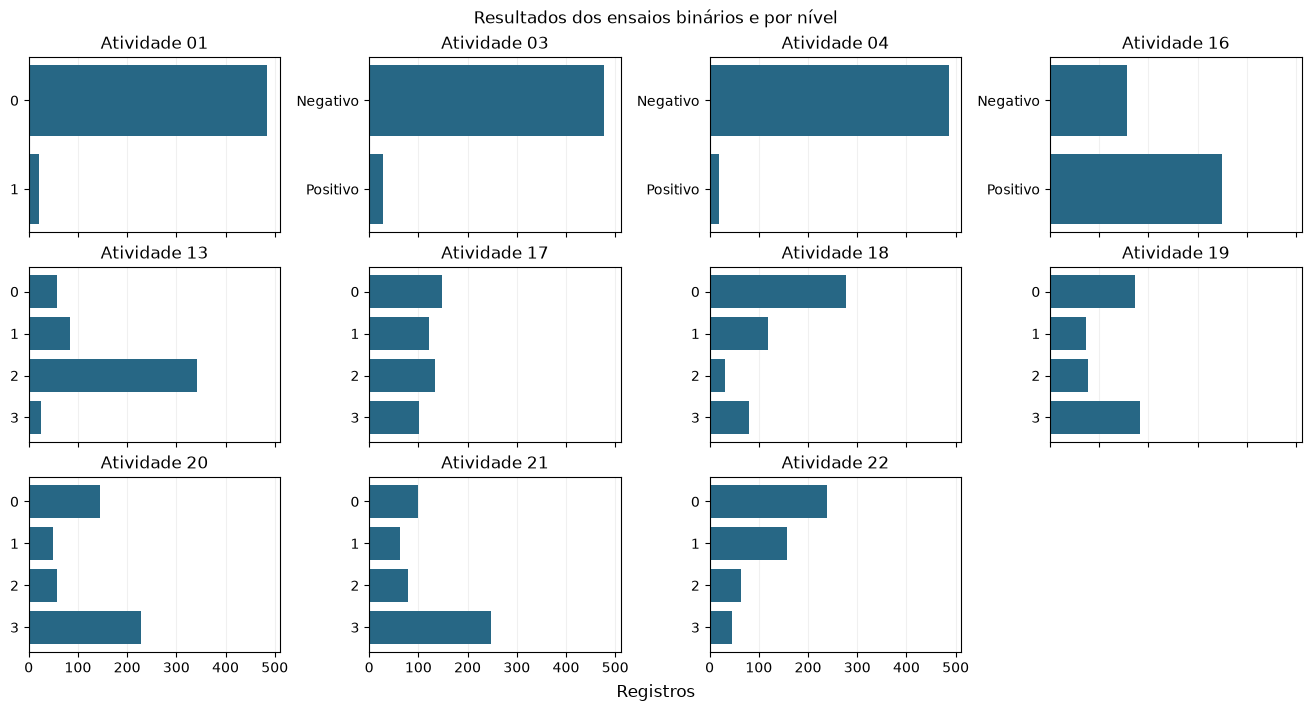

In [15]:
fig, eixos = plt.subplots(3, 4, figsize=(13, 7), sharex=True, layout="constrained")
for ax, coluna in zip(eixos.flat, binarias + ordinais):
    valores = numeros[coluna] if coluna in numeros else observados[coluna]
    barras_frequencia(ax, valores, coluna, ordenar=True)
    ax.set_xlabel("")
for ax in list(eixos.flat)[len(binarias + ordinais):]:
    ax.set_visible(False)
fig.supxlabel("Registros")
fig.suptitle("Resultados dos ensaios binários e por nível")
plt.show()

**Binárias.** Nas atividades 01, 03 e 04, o nível `0` ou a resposta `Negativo` domina, e a categoria minoritária ocorre de 19 a 28 vezes. Na Atividade 16, a maioria (349) é `Positivo`.

**Níveis de 0 a 3.** Na Atividade 13 predomina o nível 2. A 17 tem frequências relativamente próximas entre os quatro níveis. Nas atividades 18 e 22 predomina o nível 0, enquanto na 19 os níveis 0 e 3 são os mais frequentes (173 e 182 registros). Nas atividades 20 e 21 predomina o nível 3 entre os resultados observados.

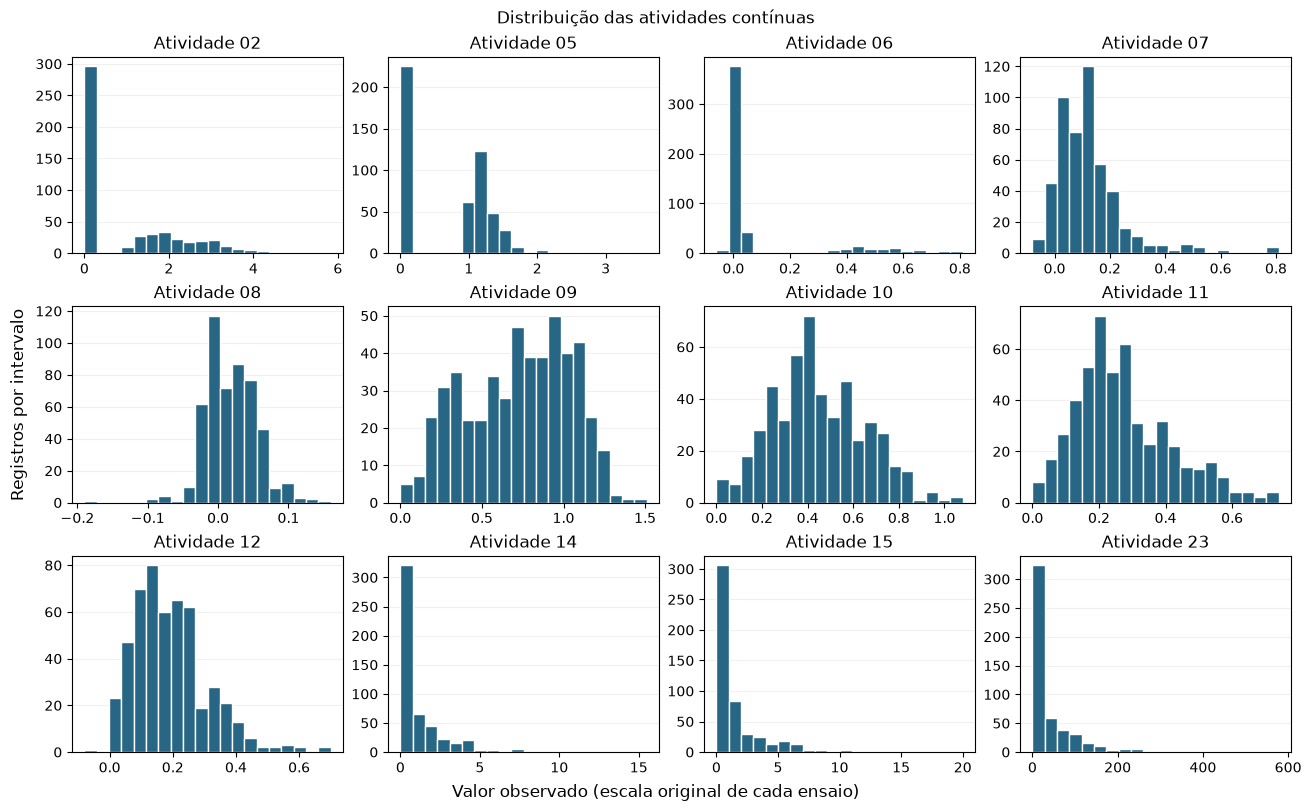

In [16]:
fig, eixos = plt.subplots(3, 4, figsize=(13, 8), layout="constrained")
for ax, coluna in zip(eixos.flat, continuas):
    ax.hist(numeros[coluna].dropna().astype(float), bins=20, color=azul, edgecolor="white")
    ax.set_title(coluna)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)
fig.supxlabel("Valor observado (escala original de cada ensaio)")
fig.supylabel("Registros por intervalo")
fig.suptitle("Distribuição das atividades contínuas")
plt.show()

**Concentração em zero.** Mais da metade dos resultados das atividades 02, 14 e 15 é exatamente zero (296, 321 e 305 registros). Na atividade 05 são 225. Nas atividades 14 e 15, a maior parte dos demais valores é baixa em relação aos máximos de 15,5 e 20, respectivamente.

**Valores próximos de zero e negativos.** As atividades 06, 07 e 08 apresentam valores negativos e positivos. As atividades 06 e 07 têm valores positivos bem acima de suas medianas, enquanto a 08 se concentra mais perto de zero. A Atividade 12 também tem um valor negativo.

**Outros padrões.** As atividades 09 e 10 apresentam valores espalhados em torno de suas medianas (0,75 e 0,42). As atividades 11 e 12 concentram mais resultados na parte baixa de seus intervalos, com alguns valores maiores. A Atividade 23 tem cauda à direita, com mediana de 12,71 e máximo de 577,89. Esse contraste motiva avaliar o efeito dos valores altos antes de decidir por uma transformação.

### Relações entre atividades

Calculamos a correlação de Spearman sobre os postos dos valores observados. As três atividades binárias textuais são representadas por `Negativo = 0` e `Positivo = 1` para este cálculo. Cada par usa apenas os registros em que ambos os ensaios têm resultado disponível. Os eixos mostram os números das atividades.

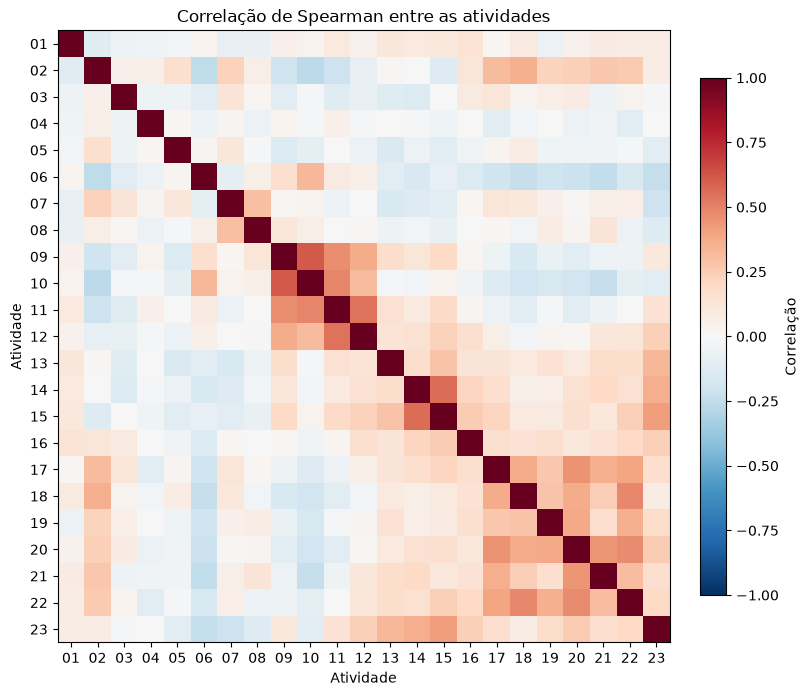

In [17]:
atividades_numericas = numeros[continuas + ordinais + ["Atividade 01"]].copy()
for coluna in ["Atividade 03", "Atividade 04", "Atividade 16"]:
    atividades_numericas[coluna] = observados[coluna].map({"Negativo": 0, "Positivo": 1})

atividades_numericas = atividades_numericas[atividades]
correlacoes = atividades_numericas.corr(method="spearman")
rotulos = [coluna.split()[-1] for coluna in atividades]
posicoes = range(len(rotulos))

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
mapa = ax.imshow(correlacoes, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(posicoes, rotulos)
ax.set_yticks(posicoes, rotulos)
ax.set(xlabel="Atividade", ylabel="Atividade", title="Correlação de Spearman entre as atividades")
fig.colorbar(mapa, ax=ax, shrink=0.8, label="Correlação")
plt.show()

As atividades 09 a 12 formam um bloco de associações positivas. O par 09–10 tem a maior correlação em magnitude (ρ ≈ 0,61), e o par 11–12 também se destaca (ρ ≈ 0,54). Fora desse bloco, as atividades 14 e 15 tendem a variar na mesma direção (ρ ≈ 0,56). São pares que vale investigar na etapa de redução de dimensionalidade por possível sobreposição de informação.

### Relações entre morfologia e GRAM

As tabelas comparam duas características: `Cor` (número de cores) e `Brilho` (código morfológico). Para essa comparação, reunimos somente as variantes inequívocas de `Positivo` e deixamos de fora dois registros com `GRAM` ambíguo. Cada barra representa 100% dos registros com a característica disponível dentro daquela categoria de `GRAM`.

Cor por GRAM (contagem)
Cor         1   2  Total
GRAM                    
Negativo  208  36    244
Positivo  191  29    220
Levedura   36   4     40

Brilho por GRAM (contagem)
Brilho    0   1  1 & 2    2  2 & 1  4  Total
GRAM                                        
Negativo  0  19      8  217      0  0    244
Positivo  2  47     17  144      7  1    218
Levedura  0  27      3    9      1  0     40



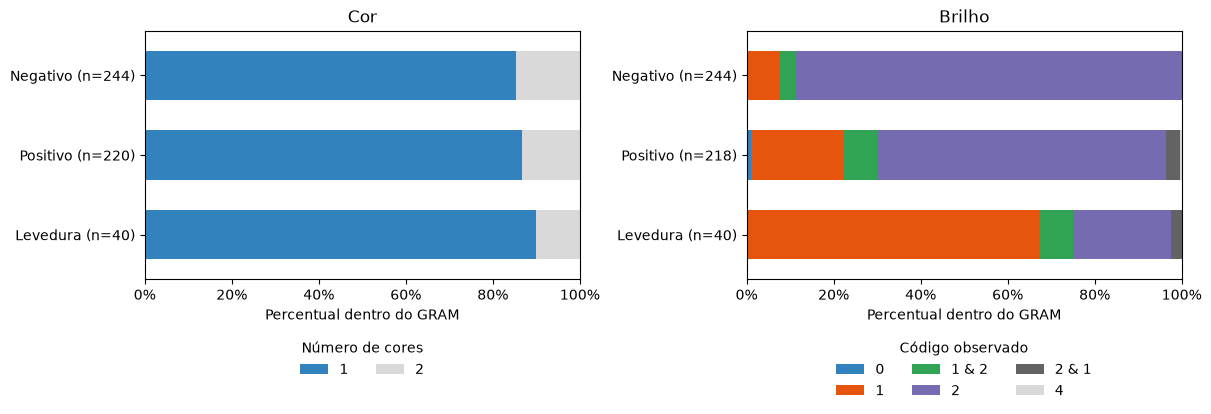

In [18]:
gram_comparacao = observados["GRAM"].replace({"POSITIVO": "Positivo", "Positiva": "Positivo"})
grupos_gram = ["Negativo", "Positivo", "Levedura"]
gram_comparacao = gram_comparacao.where(gram_comparacao.isin(grupos_gram))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.0), layout="constrained")
for ax, coluna in zip(eixos, ["Cor", "Brilho"]):
    tabela = pd.crosstab(gram_comparacao, observados[coluna]).reindex(grupos_gram)
    totais = tabela.sum(axis=1)
    percentuais = tabela.div(totais, axis=0)
    print(f"{coluna} por GRAM (contagem)")
    print(tabela.assign(Total=totais).to_string())
    print()
    percentuais.index = [f"{grupo} (n={totais[grupo]})" for grupo in grupos_gram]
    percentuais.plot.barh(stacked=True, colormap="tab20c", ax=ax, width=0.62)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set(xlim=(0, 1), xlabel="Percentual dentro do GRAM", ylabel="", title=coluna)
    ax.legend(
        title="Número de cores" if coluna == "Cor" else "Código observado",
        loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=3, frameon=False,
    )
plt.show()

**Número de cores.** Uma cor predomina nas três categorias de GRAM. A proporção varia de 85,2% entre os Gram negativos a 90,0% entre as leveduras.

**Brilho.** O código `2` predomina entre os Gram negativos (88,9%) e os positivos (66,1% dos registros com Brilho observado). Entre as leveduras, o código mais frequente é `1` (67,5%). A comparação é descritiva, com 40 registros de leveduras e mais de 200 em cada um dos outros dois grupos.